<a href="https://colab.research.google.com/github/priyadharshini201107/data_analysis/blob/main/data_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)

print("Libraries imported successfully!")

Libraries imported successfully!


In [ ]:
from google.colab import files

uploaded = files.upload()
filename = next(iter(uploaded))

df = pd.read_csv(filename, encoding="latin1")
df.columns = df.columns.str.strip()

print("Dataset loaded successfully!")
print("Dataset dimensions:", df.shape)

Saving ecommerce_sales_dataset (1).csv to ecommerce_sales_dataset (1) (1).csv
Dataset loaded successfully!
Dataset dimensions: (1005, 18)


In [ ]:
print("First five records:")
display(df.head())

print("Last five records:")
display(df.tail())

print("Column names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nDescriptive statistics:")
display(df.describe(include="all").T)

First five records:


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Segment,Country,City,State,Region,Product ID,Category,Sub-Category,Sales,Quantity,Discount,Profit
0,1,ORD-39600,2023-11-22,2023-11-24,First Class,CUST-0104,Home Office,United States,Virginia City,Virginia,South,PROD-0234,Technology,Copiers,222.76,9,0.10,58.55
1,2,ORD-60459,2023-01-14,2023-01-15,Second Class,CUST-0083,Consumer,United States,Minnesota City,Minnesota,Central,PROD-0155,Office Supplies,Binders,37.03,2,0.00,6.73
2,3,ORD-88806,2024-05-06,2024-05-09,Standard Class,CUST-0085,Home Office,United States,Georgia City,Georgia,South,PROD-0176,Technology,Accessories,352.15,7,0.15,88.69
3,4,ORD-42443,2023-11-29,2023-12-03,Second Class,CUST-0247,Corporate,United States,Georgia City,Georgia,South,PROD-0131,Office Supplies,Storage,123.47,6,0.00,8.85
4,5,ORD-36534,2024-07-17,2024-07-18,Standard Class,CUST-0074,Consumer,United States,Wisconsin City,Wisconsin,Central,PROD-0079,Furniture,Furnishings,760.11,7,0.00,49.66


Last five records:


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Segment,Country,City,State,Region,Product ID,Category,Sub-Category,Sales,Quantity,Discount,Profit
1000,779,ORD-59265,2024-04-12,2024-04-14,Second Class,CUST-0255,Consumer,United States,Florida City,Florida,South,PROD-0116,Technology,Accessories,2120.27,10,0.10,789.44
1001,335,ORD-12417,2024-11-16,2024-11-18,Standard Class,CUST-0175,Consumer,United States,Nevada City,Nevada,West,PROD-0160,Furniture,Bookcases,526.51,6,0.20,-15.88
1002,272,ORD-12229,2023-02-08,2023-02-11,Second Class,CUST-0324,Corporate,United States,New York City,New York,East,PROD-0221,Furniture,Tables,595.16,7,0.00,191.60
1003,803,ORD-34597,2024-04-06,2024-04-07,Standard Class,CUST-0253,Consumer,United States,North Carolina City,North Carolina,South,PROD-0132,Technology,Copiers,607.28,6,0.15,19.40
1004,217,ORD-98746,2024-06-08,2024-06-12,Standard Class,CUST-0268,Consumer,United States,Oregon City,Oregon,West,PROD-0052,Furniture,Tables,1799.01,6,0.15,806.18


Column names:
['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode', 'Customer ID', 'Segment', 'Country', 'City', 'State', 'Region', 'Product ID', 'Category', 'Sub-Category', 'Sales', 'Quantity', 'Discount', 'Profit']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1005 entries, 0 to 1004
Data columns (total 18 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Row ID        1005 non-null   int64  
 1   Order ID      1005 non-null   object 
 2   Order Date    1005 non-null   object 
 3   Ship Date     1005 non-null   object 
 4   Ship Mode     1001 non-null   object 
 5   Customer ID   1005 non-null   object 
 6   Segment       1005 non-null   object 
 7   Country       1005 non-null   object 
 8   City          1005 non-null   object 
 9   State         1005 non-null   object 
 10  Region        1005 non-null   object 
 11  Product ID    1005 non-null   object 
 12  Category      1005 non-null   object 


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Row ID,1005.0,NaN,NaN,NaN,500.40398,288.667574,1.0,251.0,500.0,751.0,1000.0
Order ID,1005,995,ORD-12417,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Order Date,1005,543,2024-12-16,6,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Ship Date,1005,550,2023-07-26,6,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Ship Mode,1001,4,Standard Class,587,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Customer ID,1005,334,CUST-0236,8,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Segment,1005,3,Consumer,570,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Country,1005,1,United States,1005,NaN,NaN,NaN,NaN,NaN,NaN,NaN
City,1005,16,Virginia City,69,NaN,NaN,NaN,NaN,NaN,NaN,NaN
State,1005,16,Virginia,69,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
print("Missing values before cleaning:")
print(df.isnull().sum())

print("\nDuplicate records:", df.duplicated().sum())

df = df.drop_duplicates().copy()

numeric_cols = df.select_dtypes(include=np.number).columns
categorical_cols = df.select_dtypes(
    include=["object", "category", "string"]
).columns

for col in numeric_cols:
    df[col] = df[col].fillna(df[col].median())

for col in categorical_cols:
    if df[col].isnull().any():
        mode_values = df[col].mode()
        if not mode_values.empty:
            df[col] = df[col].fillna(mode_values.iloc[0])

print("\nMissing values after cleaning:", df.isnull().sum().sum())
print("Cleaned dataset shape:", df.shape)

Missing values before cleaning:
Row ID          0
Order ID        0
Order Date      0
Ship Date       0
Ship Mode       4
Customer ID     0
Segment         0
Country         0
City            0
State           0
Region          0
Product ID      0
Category        0
Sub-Category    0
Sales           0
Quantity        0
Discount        5
Profit          8
dtype: int64

Duplicate records: 5

Missing values after cleaning: 0
Cleaned dataset shape: (1000, 18)


In [ ]:
features = ["Sales", "Profit", "Quantity", "Discount"]
features = [col for col in features if col in df.columns]

X = df[features].replace([np.inf, -np.inf], np.nan)
X = X.fillna(X.median())

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Features used:", features)
print("Scaled data shape:", X_scaled.shape)

Features used: ['Sales', 'Profit', 'Quantity', 'Discount']
Scaled data shape: (1000, 4)


Records in each product category:
Category
Office Supplies    408
Furniture          335
Technology         257
Name: count, dtype: int64


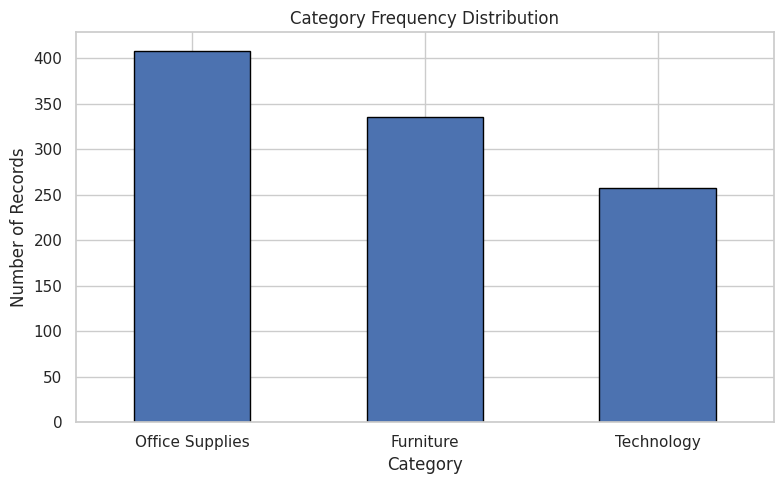

In [ ]:
if "Category" in df.columns:
    print("Records in each product category:")
    print(df["Category"].value_counts())

    df["Category"].value_counts().plot(
        kind="bar", edgecolor="black"
    )
    plt.title("Category Frequency Distribution")
    plt.xlabel("Category")
    plt.ylabel("Number of Records")
    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.show()

In [ ]:
pca = PCA(n_components=2)
principal_components = pca.fit_transform(X_scaled)

pca_df = pd.DataFrame(
    principal_components,
    columns=["PC1", "PC2"]
)

print("PCA transformation completed.")
print("Explained variance ratio:",
      np.round(pca.explained_variance_ratio_, 4))

print("Total variance explained (%):",
      round(pca.explained_variance_ratio_.sum() * 100, 2))

PCA transformation completed.
Explained variance ratio: [0.5289 0.2634]
Total variance explained (%): 79.24


In [ ]:
print("PCA components shape:", pca.components_.shape)
print("PCA transformation ready for visualization.")

PCA components shape: (2, 4)
PCA transformation ready for visualization.


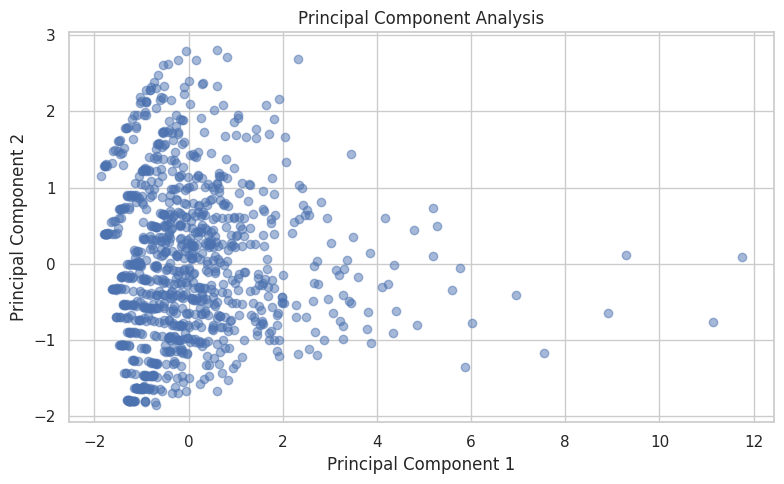

In [ ]:
plt.scatter(pca_df["PC1"], pca_df["PC2"], alpha=0.5)
plt.title("Principal Component Analysis")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.tight_layout()
plt.show()

In [ ]:
print("Predictive model training is not performed.")
print("PCA explained variance:",
      np.round(pca.explained_variance_ratio_, 4))

Predictive model training is not performed.
PCA explained variance: [0.5289 0.2634]


In [ ]:
print("Number of numerical features:", len(features))
print("Number of principal components:", pca.n_components_)
print("Explained variance by each component:",
      np.round(pca.explained_variance_ratio_, 4))

Number of numerical features: 4
Number of principal components: 2
Explained variance by each component: [0.5289 0.2634]


In [ ]:
correlation = df[features].corr()
display(correlation.round(3))

,Sales,Profit,Quantity,Discount
Sales,1.000,0.815,0.430,-0.085
Profit,0.815,1.000,0.318,-0.272
Quantity,0.430,0.318,1.000,0.033
Discount,-0.085,-0.272,0.033,1.000


In [ ]:
def highest_sales_category(data):
    return data.groupby("Category")["Sales"].sum().idxmax()

print("Category with highest total sales:",
      highest_sales_category(df))

Category with highest total sales: Technology


In [ ]:
df.to_csv("cleaned_superstore.csv", index=False)
print("Cleaned dataset saved successfully.")

from google.colab import files
files.download("cleaned_superstore.csv")

Cleaned dataset saved successfully.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

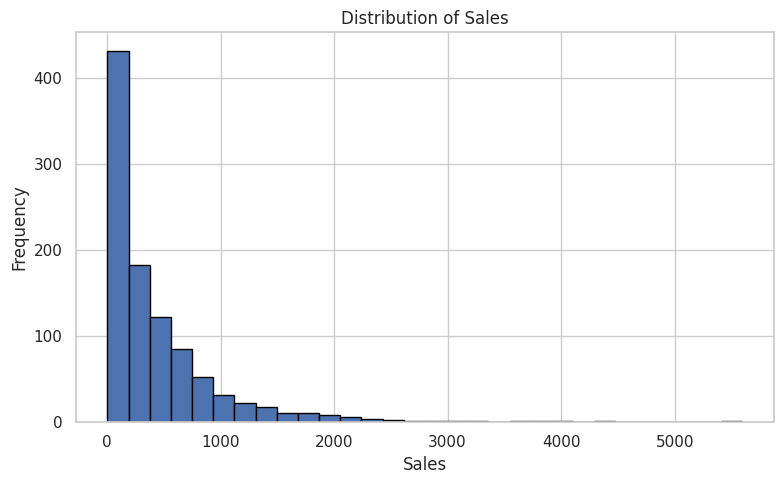

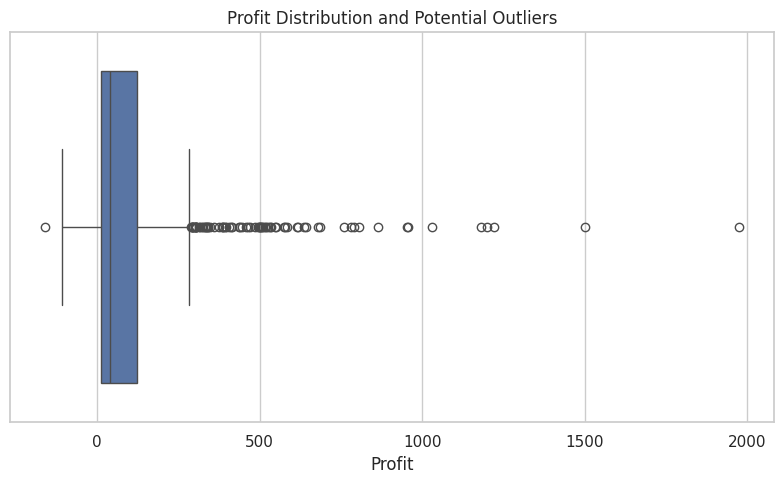

In [ ]:
df["Sales"].hist(bins=30, edgecolor="black")
plt.title("Distribution of Sales")
plt.xlabel("Sales")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

sns.boxplot(x=df["Profit"])
plt.title("Profit Distribution and Potential Outliers")
plt.tight_layout()
plt.show()

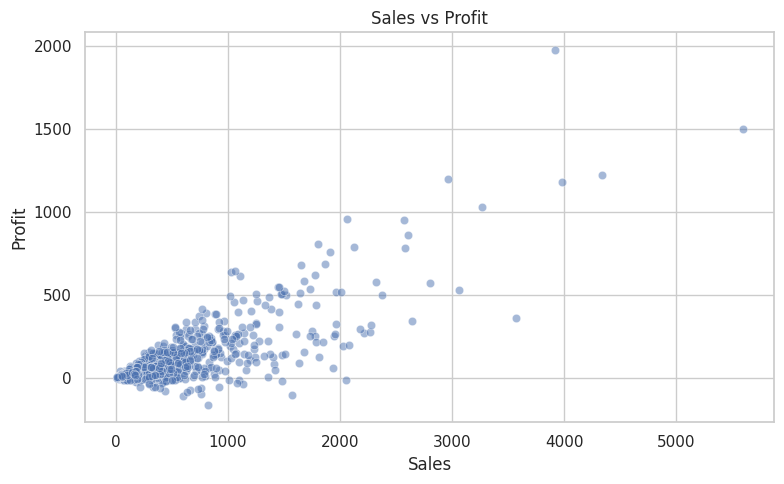

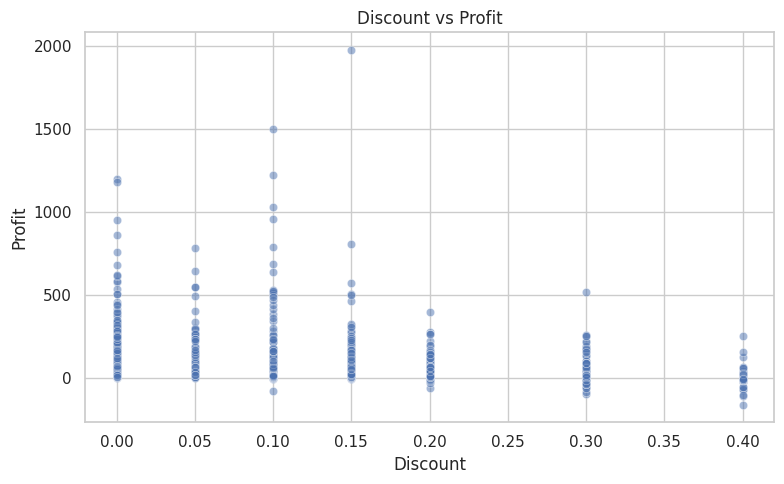

Sales-Profit correlation: 0.815


In [ ]:
sns.scatterplot(data=df, x="Sales", y="Profit", alpha=0.5)
plt.title("Sales vs Profit")
plt.tight_layout()
plt.show()

sns.scatterplot(data=df, x="Discount", y="Profit", alpha=0.5)
plt.title("Discount vs Profit")
plt.tight_layout()
plt.show()

print("Sales-Profit correlation:",
      round(df["Sales"].corr(df["Profit"]), 3))

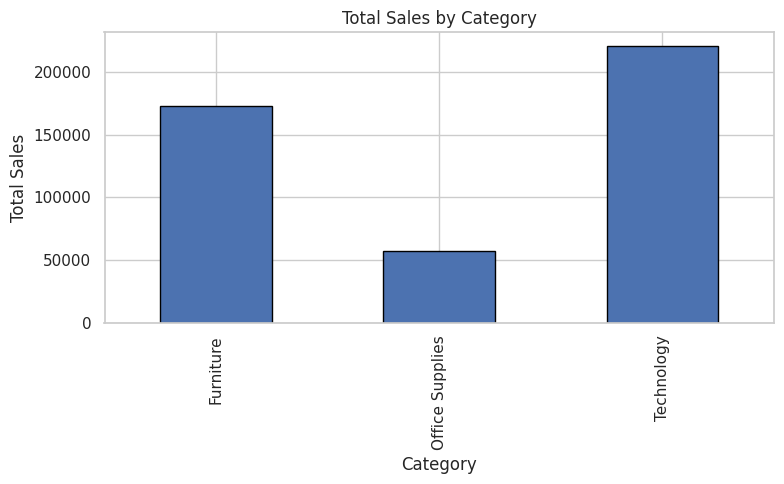

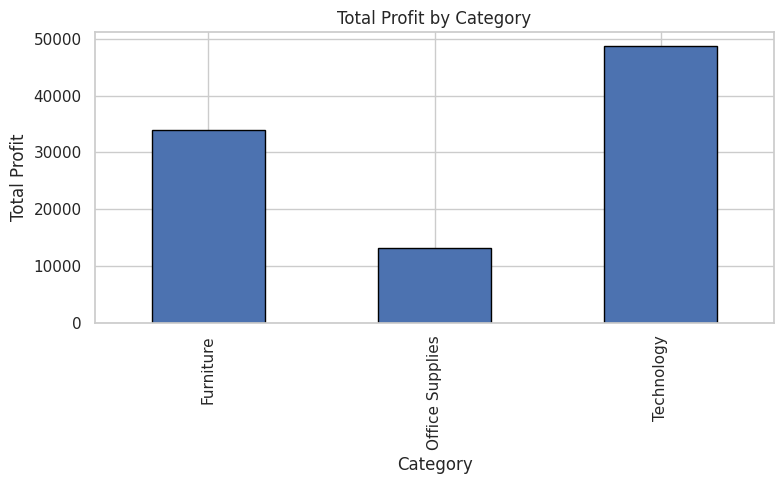

In [ ]:
category_sales = df.groupby("Category")["Sales"].sum()
category_profit = df.groupby("Category")["Profit"].sum()

category_sales.plot(kind="bar", edgecolor="black")
plt.title("Total Sales by Category")
plt.ylabel("Total Sales")
plt.tight_layout()
plt.show()

category_profit.plot(kind="bar", edgecolor="black")
plt.title("Total Profit by Category")
plt.ylabel("Total Profit")
plt.tight_layout()
plt.show()

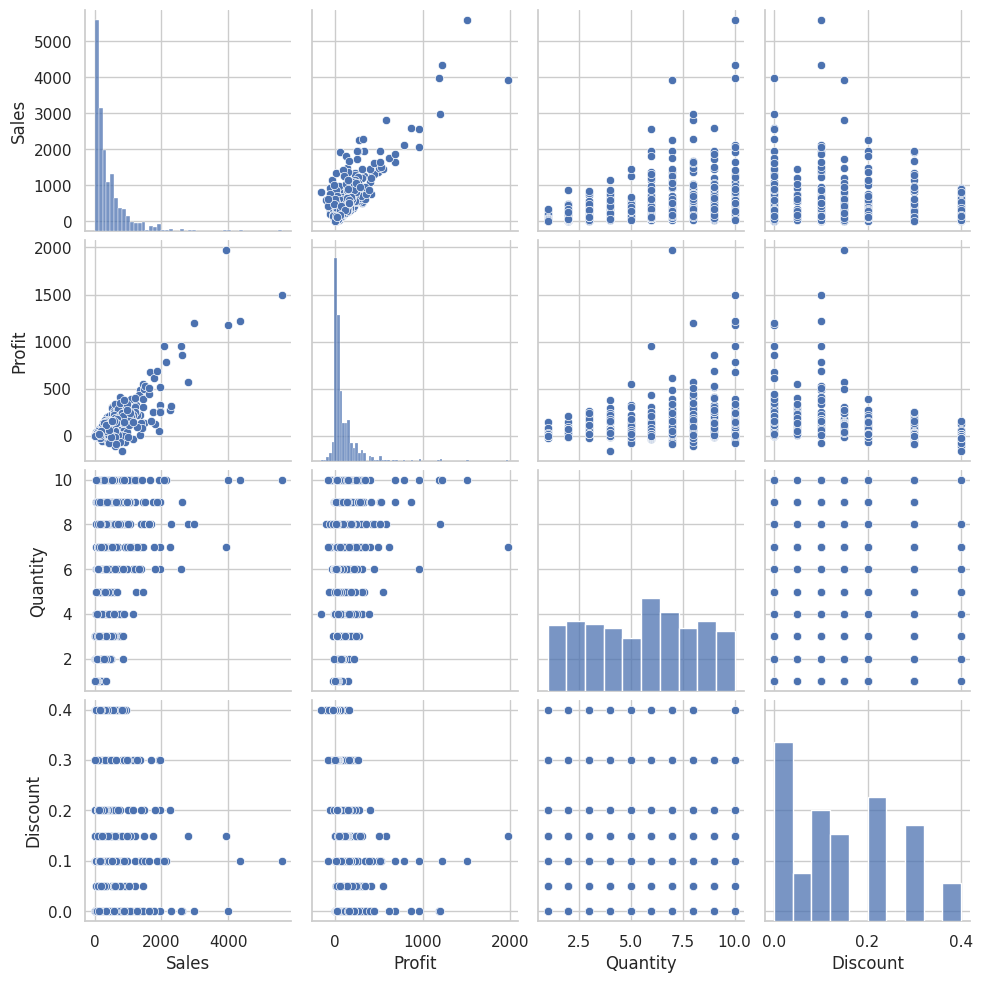

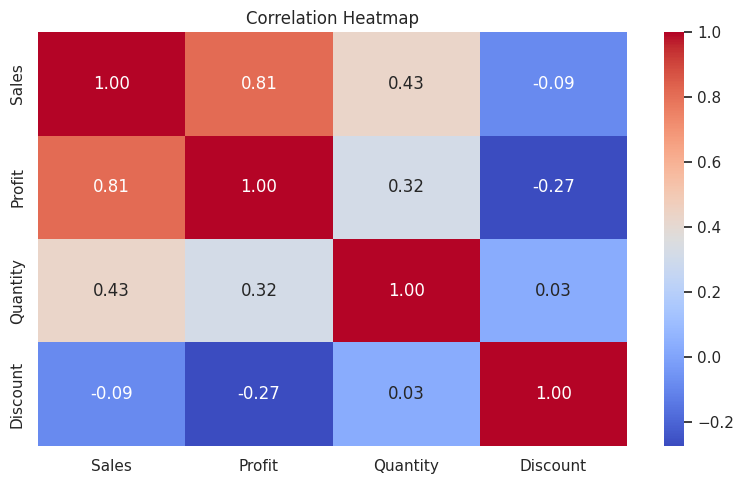

In [ ]:
sns.pairplot(
    df[features].sample(min(500, len(df)), random_state=42),
    diag_kind="hist"
)
plt.show()

sns.heatmap(
    df[features].corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

In [ ]:
fig = px.scatter(
    df,
    x="Sales",
    y="Profit",
    color="Category",
    hover_data=["Quantity", "Discount"],
    title="Interactive Sales and Profit Analysis"
)
fig.show()

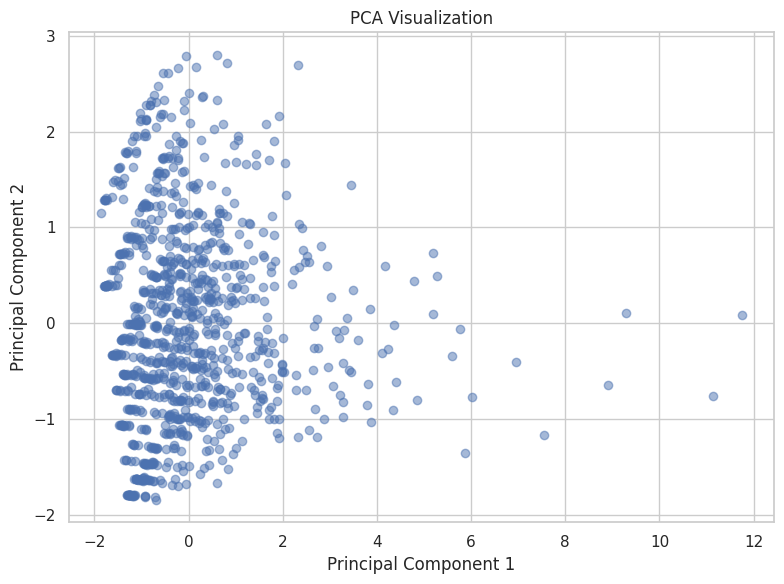

In [ ]:
plt.figure(figsize=(8, 6))
plt.scatter(pca_df["PC1"], pca_df["PC2"], alpha=0.5)
plt.title("PCA Visualization")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.tight_layout()
plt.show()